# __Appendix A__

## Signature Assignment 8: Compose an Academic Paper for a Data Science Study
### Comparing GAM vs SARIMAX and Direct GAM vs Recursive GAM to forecast PIC deaths

Dawud Ujamaa  
School of Technology & Engineering, National University  
DDS-7255: Advanced Research Design in Data Science  
Dr. Seyedmohsen Hosseini  
October 18, 2026

Notebook started at: 2026-10-18 20:40:55


**Figure A1**

*Distribution of values in State Variable in Dataset*

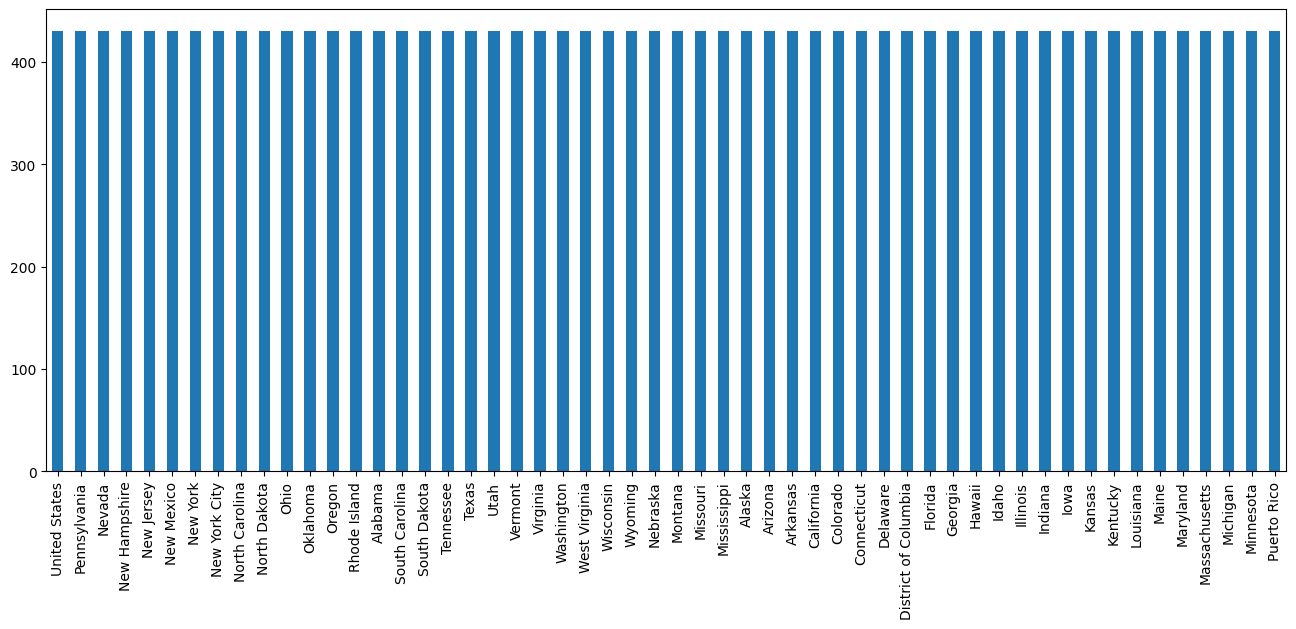

In [1]:
# Run notebook 1. Business and Data Understanding
%run UjamaaDDDS7255-8-1.Business_and_Data_Understanding.ipynb

### __3: Data Preparation__ 
#### __3.1: Data Cleaning and Preprocessing__ 

In [2]:
# Filter to only weekly time series for the United States and only keep variables needed for model
PICUS = PIC[(PIC['State'] == 'United States') & (PIC['Group'] == 'By Week')]
PICUS = PICUS[['Group','Week Ending Date','State','Pneumonia, Influenza, or COVID-19 Deaths']]
PICUS.rename(columns={'Pneumonia, Influenza, or COVID-19 Deaths': 'PIC_Deaths'}, inplace=True)
PICUS

,Group,Week Ending Date,State,PIC_Deaths
0,By Week,2020-01-04,United States,4545.0
1,By Week,2020-01-11,United States,4628.0
2,By Week,2020-01-18,United States,4534.0
3,By Week,2020-01-25,United States,4418.0
4,By Week,2020-02-01,United States,4299.0
...,...,...,...,...
338,By Week,2026-06-27,United States,2791.0
339,By Week,2026-07-04,United States,2660.0
340,By Week,2026-07-11,United States,2472.0
341,By Week,2026-07-18,United States,2059.0


**Figure A2**

*Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 01/04/2020 - 07/25/2026*

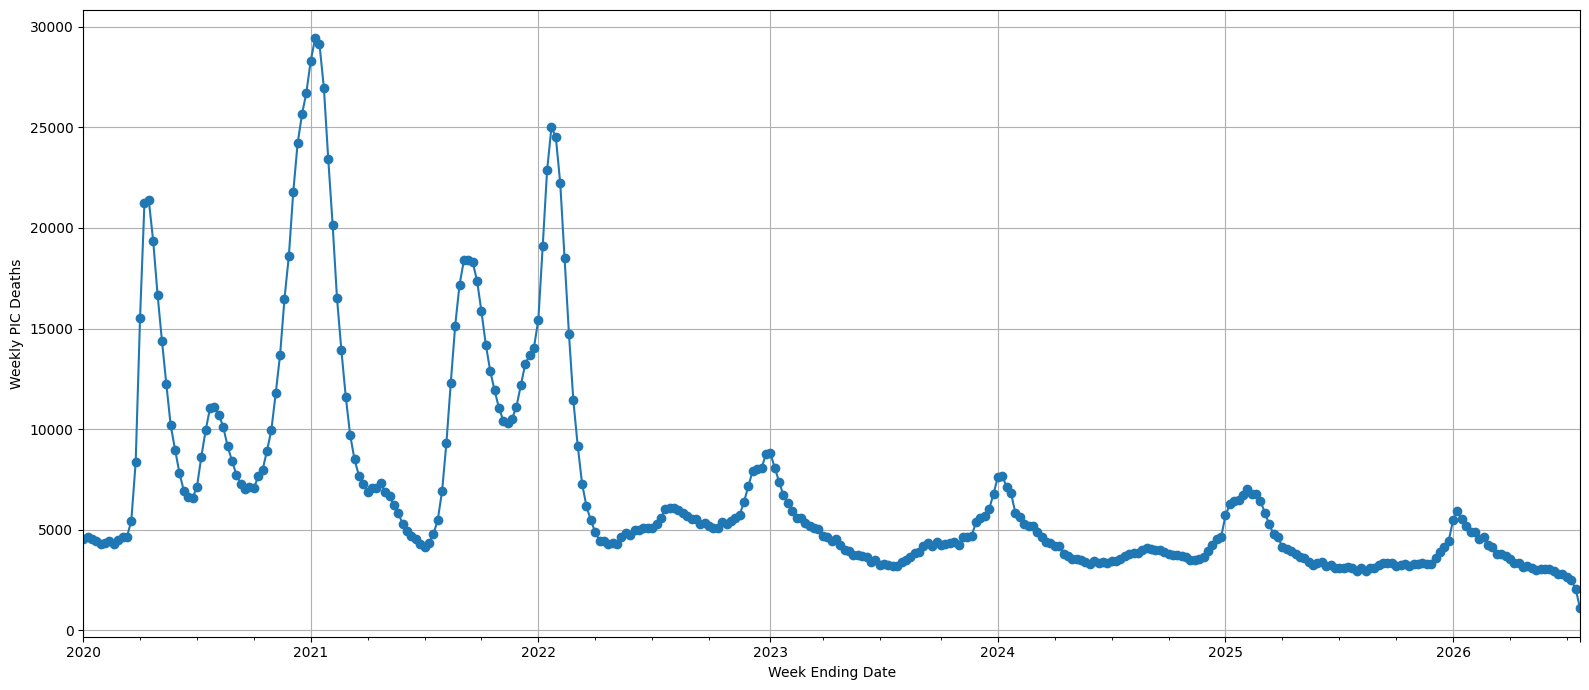

In [3]:
display(Markdown("**Figure A2**"))
display(Markdown("*Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 01/04/2020 - 07/25/2026*"))

PICUS = PICUS.sort_values("Week Ending Date").set_index("Week Ending Date")
PICUS["PIC_Deaths"].plot(figsize=(16, 7), marker="o")

plt.xlabel("Week Ending Date")
plt.ylabel("Weekly PIC Deaths")
plt.grid(True)
plt.tight_layout()
plt.show()

*Note.* This figure shows Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 01/04/2020 - 07/25/2026. 
<div style="page-break-before: always;"></div>

**Figure A3**

*Boxplot Showing Distribution of Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 01/04/2020 - 07/25/2026*

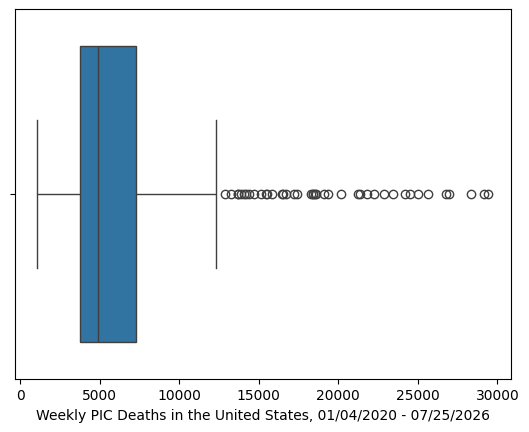

In [4]:
# boxplot to check for outliers in weekly hospitalization rate estimate

sns.boxplot(x=PICUS["PIC_Deaths"])

display(Markdown("**Figure A3**"))
display(Markdown("*Boxplot Showing Distribution of Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 01/04/2020 - 07/25/2026*"))
plt.xlabel("Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026")
plt.show();

In [5]:
PICUS["PIC_Deaths"].describe()

count      343.000000
mean      6938.139942
std       5286.596212
min       1087.000000
25%       3757.500000
50%       4918.000000
75%       7278.000000
max      29426.000000
Name: PIC_Deaths, dtype: float64

In [6]:
# check for missing values
print(PICUS.isnull().sum())

Group         0
State         0
PIC_Deaths    0
dtype: int64


**Figure A4**

*Autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026*

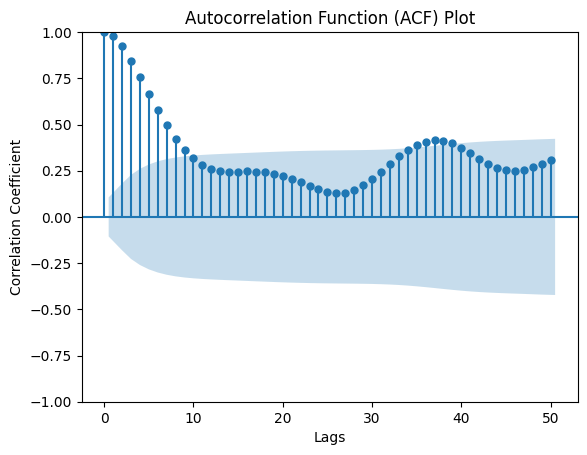

In [7]:
# Calculate and plot autocorrelation values 

display(Markdown("**Figure A4**"))
display(Markdown("*Autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026*"))

acf_values = acf(PICUS["PIC_Deaths"], nlags=50)

plot_acf(PICUS["PIC_Deaths"], lags=50)
plt.title("Autocorrelation Function (ACF) Plot")
plt.xlabel("Lags")
plt.ylabel("Correlation Coefficient")
plt.show()

*Note.* This figure shows the Autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026. 
<div style="page-break-before: always;"></div>

**Figure A5**

*Partial autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026*

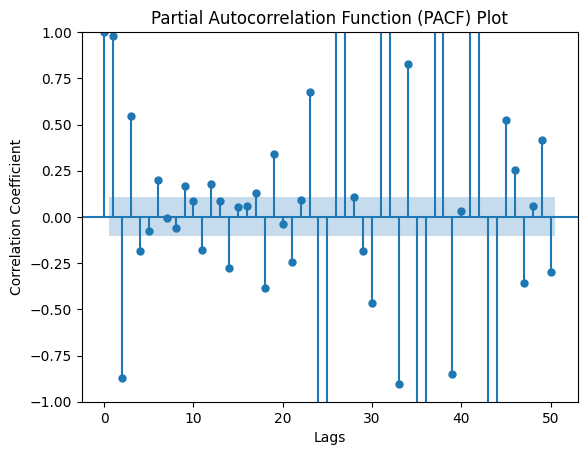

In [8]:
# Calculate and plot partial autocorrelation values 

display(Markdown("**Figure A5**"))
display(Markdown("*Partial autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026*"))

pacf_values = pacf(PICUS["PIC_Deaths"], nlags=50, method='ywadjusted')

plot_pacf(PICUS["PIC_Deaths"], lags=50, method='ywadjusted')
plt.title("Partial Autocorrelation Function (PACF) Plot")
plt.xlabel("Lags")
plt.ylabel("Correlation Coefficient")
plt.show()

*Note.* This figure shows the Partial autocorrelation plot of Weekly PIC Deaths in the United States, 01/04/2020 - 07/25/2026. 
<div style="page-break-before: always;"></div>

Since COVID-19 pandemic dates have extremely large values, and the 8 most recent weeks have extremely low values (likely due to incomplete data and delayed reporting), the time series will be restricted to dates between 08/11/2022 (CDC shifts toward managing COVID rather than extraordinary restrictions https://www.cdc.gov/mmwr/volumes/71/wr/mm7133e1.htm) and 06/13/2026

In [9]:
PICUS = PICUS.loc["2022-08-11":"2026-06-13"]
PICUS

,Group,State,PIC_Deaths
Week Ending Date,,,
2022-08-13,By Week,United States,5971.0
2022-08-20,By Week,United States,5810.0
2022-08-27,By Week,United States,5695.0
2022-09-03,By Week,United States,5512.0
2022-09-10,By Week,United States,5517.0
...,...,...,...
2026-05-16,By Week,United States,2993.0
2026-05-23,By Week,United States,3056.0
2026-05-30,By Week,United States,3050.0


**Figure A6**

*Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026*

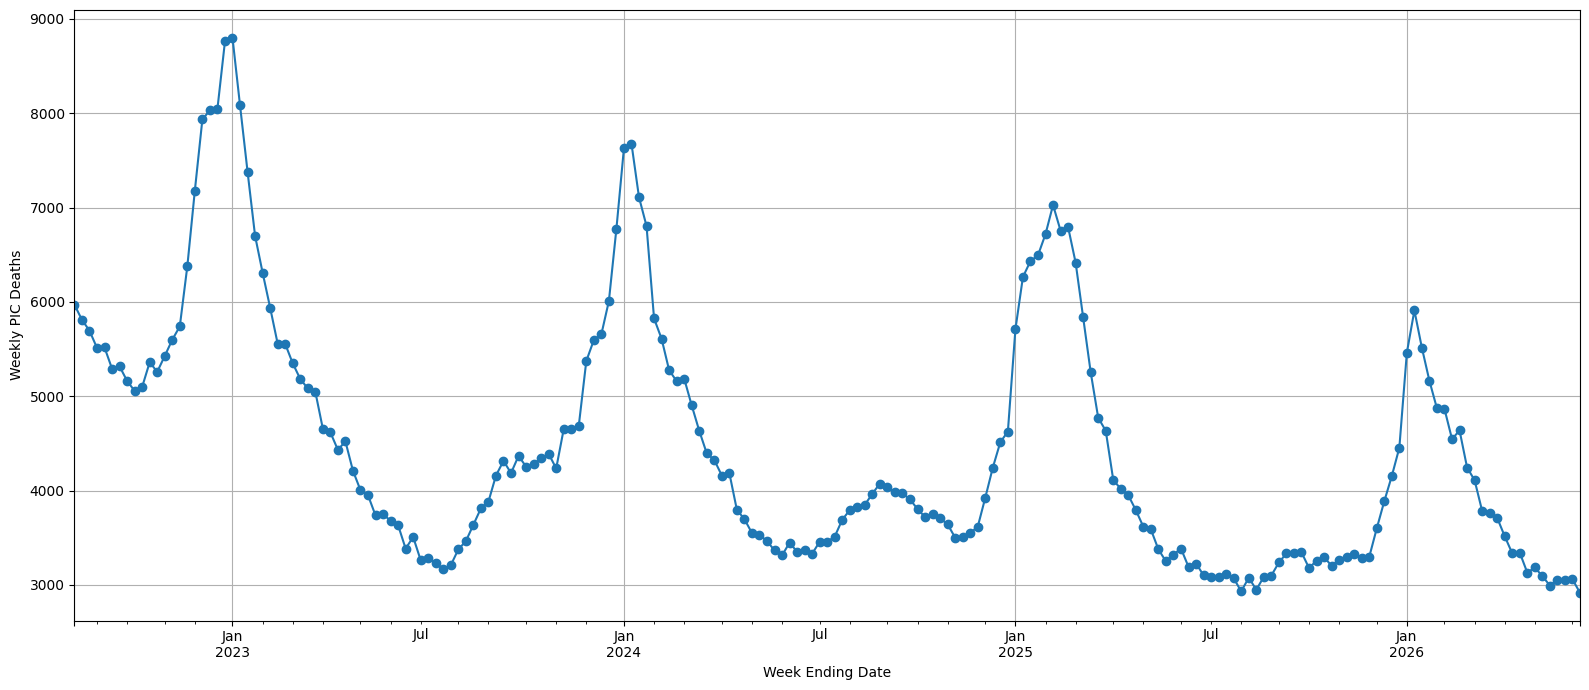

In [10]:
display(Markdown("**Figure A6**"))
display(Markdown("*Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026*"))

PICUS["PIC_Deaths"].plot(figsize=(16, 7), marker="o")

plt.xlabel("Week Ending Date")
plt.ylabel("Weekly PIC Deaths")
plt.grid(True)
plt.tight_layout()
plt.show()

*Note.* This figure shows Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026. 
<div style="page-break-before: always;"></div>

**Figure A7**

*Decomposition of Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026*

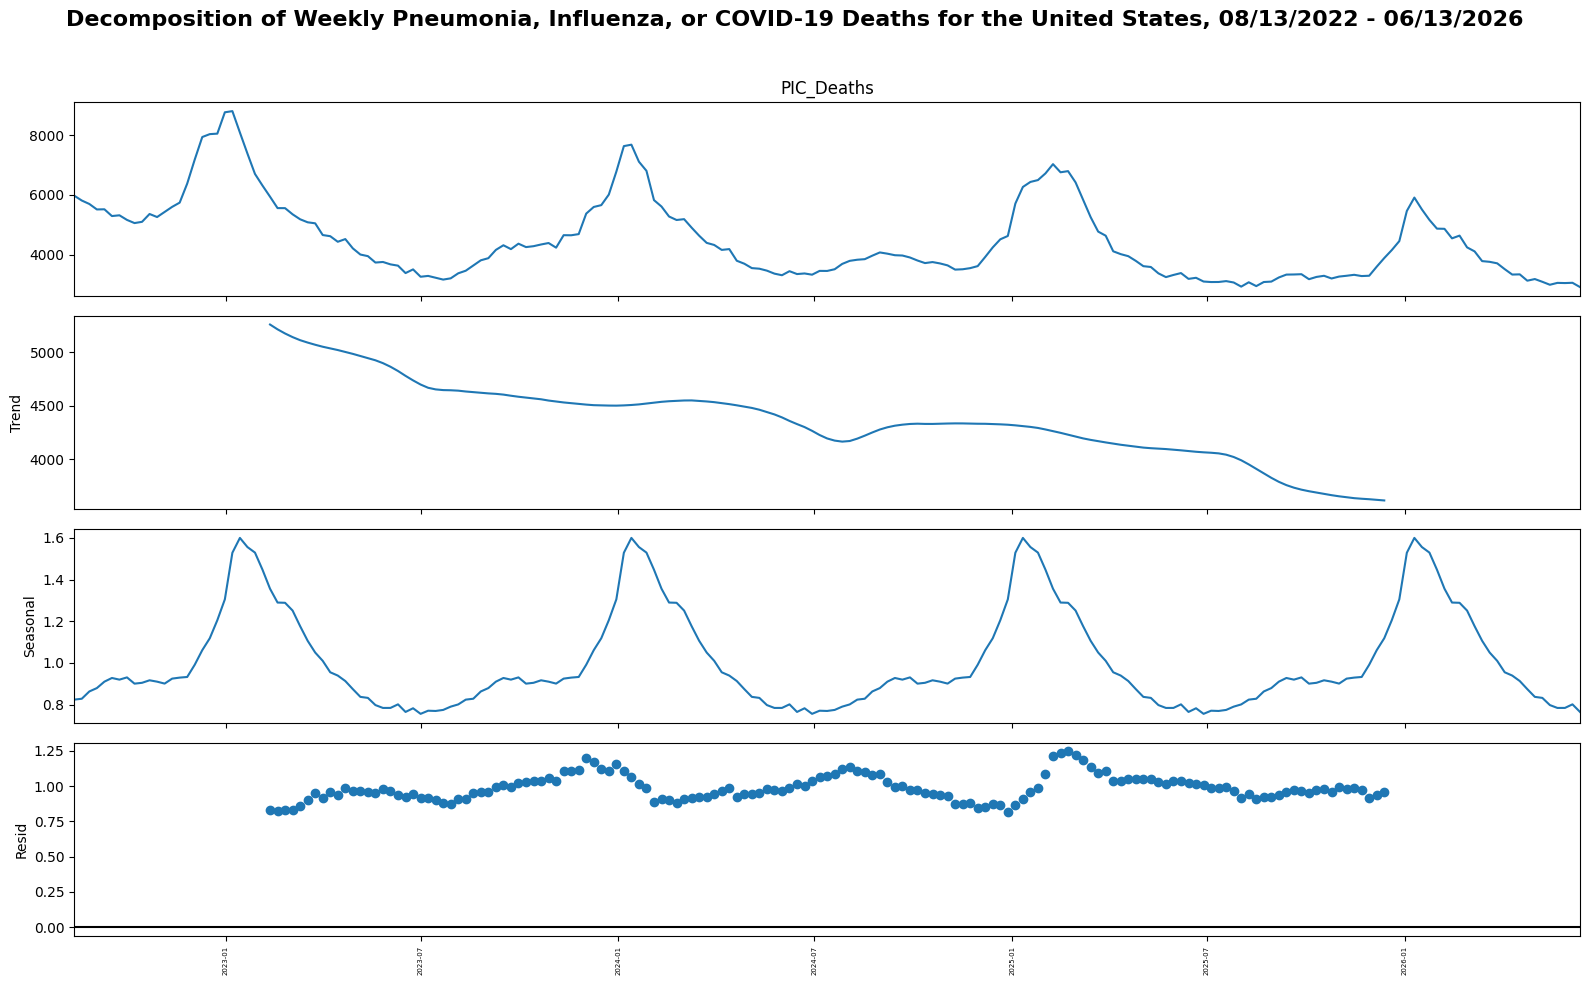

In [11]:
# decompose the time series

display(Markdown("**Figure A7**"))
display(Markdown("*Decomposition of Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026*"))

decomposition = seasonal_decompose(
    PICUS["PIC_Deaths"],
    #model="additive",
    model="multiplicative",
    period=52
)

# Plot the decomposition
fig = decomposition.plot()
fig.suptitle("Decomposition of Weekly Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026", 
             fontsize=16, fontweight="bold")
fig.set_size_inches(16, 10)
# Rotate x-axis labels on all subplots
for ax in fig.axes:
    ax.tick_params(axis="x", labelrotation=90, labelsize=5)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

*Note.* This figure shows the decompositon of the Weekly time series of Pneumonia, Influenza, or COVID-19 Deaths for the United States, 08/13/2022 - 06/13/2026. 
<div style="page-break-before: always;"></div>

#### __3.2: Feature Engineering: Feature Creation__ 
Create new features based on domain knowledge

In [12]:
# numeric index for time trend
PICUS['time_idx'] = np.arange(len(PICUS)).astype('float64') 

# Create Lagged features up to 4 weeks
PICUS['lag1'] = PICUS["PIC_Deaths"].shift(1)
PICUS['lag2'] = PICUS["PIC_Deaths"].shift(2)
PICUS['lag3'] = PICUS["PIC_Deaths"].shift(3)
PICUS['lag4'] = PICUS["PIC_Deaths"].shift(4)

# create seasonal lags
PICUS['lag52'] = PICUS["PIC_Deaths"].shift(52)
PICUS['lag53'] = PICUS["PIC_Deaths"].shift(53)
PICUS['lag104'] = PICUS["PIC_Deaths"].shift(104)

# create 3-week and 4-week rolling average
PICUS['3WKmean'] = (PICUS["PIC_Deaths"].shift(1).rolling(3).mean())
PICUS['4WKmean'] = (PICUS["PIC_Deaths"].shift(1).rolling(4).mean())

# exponentially weighted moving average (EWMA)
PICUS['EWMA'] = (PICUS["PIC_Deaths"].shift(1).ewm(span=3, adjust=False).mean())

# trailing volatility
PICUS['rollstd4'] = PICUS["PIC_Deaths"].shift(1).rolling(window=4).std()
PICUS['rollstd8'] = PICUS["PIC_Deaths"].shift(1).rolling(window=8).std()

# changes in recent activity
PICUS['change_1'] = PICUS["PIC_Deaths"].shift(1) - PICUS["PIC_Deaths"].shift(2)
PICUS['change_4'] = PICUS["PIC_Deaths"].shift(1) - PICUS["PIC_Deaths"].shift(5)

# Fourier terms for 6-month and 12-month seasonality
t = np.arange(len(PICUS))

# 6-month (26 weeks) seasonality 
for k in range(1, 4):
    PICUS[f"26WK_sin_{k}"] = np.sin(2 * np.pi * k * t / 26)
    PICUS[f"26WK_cos_{k}"] = np.cos(2 * np.pi * k * t / 26)

# 12-month (52 weeks) seasonality 
for k in range(1, 4):
    PICUS[f"52WK_sin_{k}"] = np.sin(2 * np.pi * k * t / 52)
    PICUS[f"52WK_cos_{k}"] = np.cos(2 * np.pi * k * t / 52)

# replace NaN with 0
PICUS = PICUS.fillna(0)

PICUS

,Group,State,PIC_Deaths,time_idx,lag1,lag2,lag3,lag4,lag52,lag53,...,26WK_sin_2,26WK_cos_2,26WK_sin_3,26WK_cos_3,52WK_sin_1,52WK_cos_1,52WK_sin_2,52WK_cos_2,52WK_sin_3,52WK_cos_3
Week Ending Date,,,,,,,,,,,,,,,,,,,,,
2022-08-13,By Week,United States,5971.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2022-08-20,By Week,United States,5810.0,1.0,5971.0,0.0,0.0,0.0,0.0,0.0,...,0.464723,0.885456,0.663123,0.748511,0.120537,0.992709,0.239316,0.970942,0.354605,0.935016
2022-08-27,By Week,United States,5695.0,2.0,5810.0,5971.0,0.0,0.0,0.0,0.0,...,0.822984,0.568065,0.992709,0.120537,0.239316,0.970942,0.464723,0.885456,0.663123,0.748511
2022-09-03,By Week,United States,5512.0,3.0,5695.0,5810.0,5971.0,0.0,0.0,0.0,...,0.992709,0.120537,0.822984,-0.568065,0.354605,0.935016,0.663123,0.748511,0.885456,0.464723
2022-09-10,By Week,United States,5517.0,4.0,5512.0,5695.0,5810.0,5971.0,0.0,0.0,...,0.935016,-0.354605,0.239316,-0.970942,0.464723,0.885456,0.822984,0.568065,0.992709,0.120537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-16,By Week,United States,2993.0,196.0,3092.0,3184.0,3129.0,3341.0,3375.0,3587.0,...,0.464723,0.885456,-0.663123,-0.748511,-0.992709,0.120537,-0.239316,-0.970942,0.935016,-0.354605
2026-05-23,By Week,United States,3056.0,197.0,2993.0,3092.0,3184.0,3129.0,3249.0,3375.0,...,0.822984,0.568065,-0.992709,-0.120537,-0.970942,0.239316,-0.464723,-0.885456,0.748511,-0.663123
2026-05-30,By Week,United States,3050.0,198.0,3056.0,2993.0,3092.0,3184.0,3321.0,3249.0,...,0.992709,0.120537,-0.822984,0.568065,-0.935016,0.354605,-0.663123,-0.748511,0.464723,-0.885456


#### __3.3: Train/Test Split__ 

In [13]:
# change date to weekly frequency of Saturday
df = PICUS.asfreq("W-SAT")

# define target variable
y = df['PIC_Deaths'].astype(float)

# define exogenous variables
X_cols = ['time_idx','lag1','lag2','lag3','lag4','lag52', 'lag53','lag104','3WKmean',
          '4WKmean','EWMA','rollstd4','rollstd8','change_1','change_4',
         '26WK_sin_1','26WK_cos_1','26WK_sin_2','26WK_cos_2','26WK_sin_3','26WK_cos_3',
         '52WK_sin_1','52WK_cos_1','52WK_sin_2','52WK_cos_2','52WK_sin_3','52WK_cos_3']

# test split will use 40 weeks ~20%
test_size = 40
train = y.iloc[:-test_size]
test = y.iloc[-test_size:]

train_X = df[X_cols].iloc[:-test_size]
test_X = df[X_cols].iloc[-test_size:]

#validation will use 30 weeks ~15%
val_size = 30
val_train = train.iloc[:-val_size]
val_test = train.iloc[-val_size:]

val_train_X = train_X.iloc[:-val_size]
val_test_X = train_X.iloc[-val_size:]

print("Training observations:", len(train))
print("Hold-out Test observations:", len(test))

print("Validation Training observations:", len(val_train))
print("Validation Testing observations:", len(val_test))

Training observations: 161
Hold-out Test observations: 40
Validation Training observations: 131
Validation Testing observations: 30


**Figure A8**

*Correlation Matrix on Training Set*

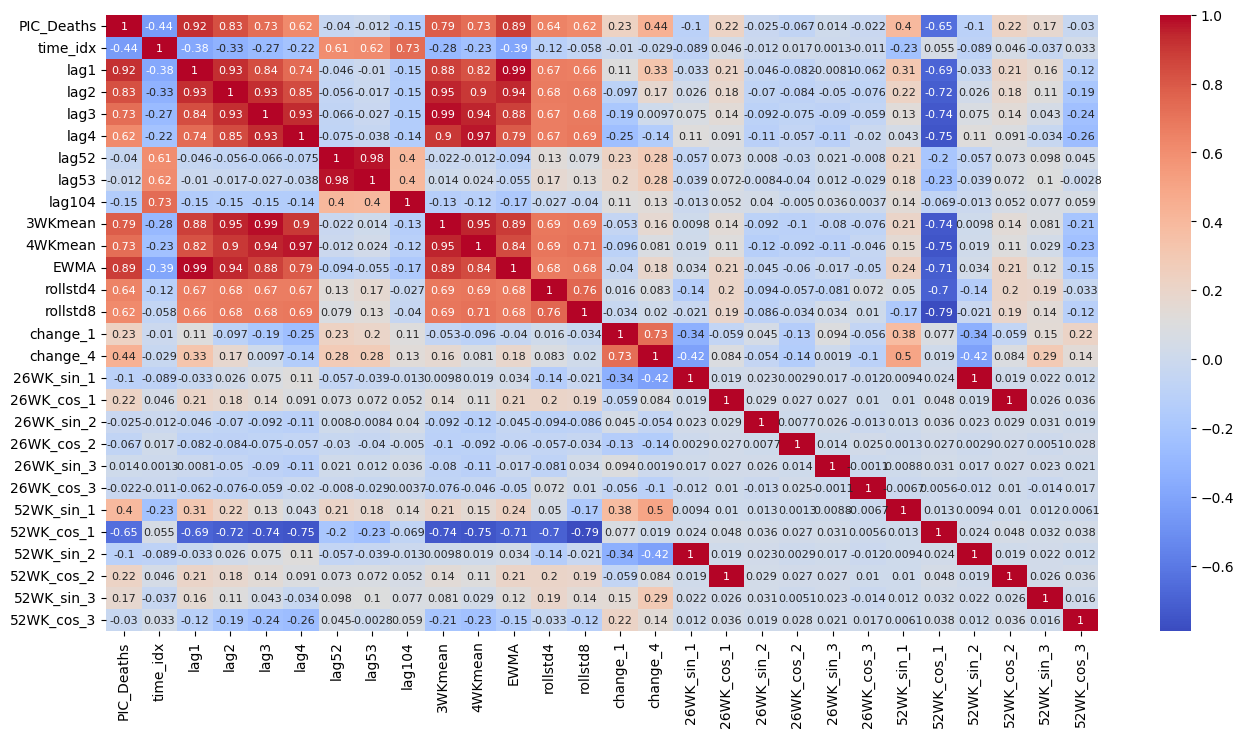

In [14]:
# correlation matrix 

display(Markdown("**Figure A8**"))
display(Markdown("*Correlation Matrix on Training Set*"))

cols = ['PIC_Deaths','time_idx','lag1','lag2','lag3','lag4','lag52', 'lag53','lag104','3WKmean',
          '4WKmean','EWMA','rollstd4','rollstd8','change_1','change_4',
         '26WK_sin_1','26WK_cos_1','26WK_sin_2','26WK_cos_2','26WK_sin_3','26WK_cos_3',
         '52WK_sin_1','52WK_cos_1','52WK_sin_2','52WK_cos_2','52WK_sin_3','52WK_cos_3']

TRAIN_FULL = train_X.copy()
TRAIN_FULL['PIC_Deaths'] = train

plt.figure(figsize=(16, 8)) 
corr_matrix = TRAIN_FULL[cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', annot_kws={'size': 8})
plt.show()

*Note.* This figure shows a correlation matrix for the target variable and created features in the training dataset. 
<div style="page-break-before: always;"></div>

#### __3.4: Standardize Features__ 

In [15]:
# standardize the training dataset 
scaler = StandardScaler(with_std=True , with_mean=True)
train_X_scaled = scaler.fit_transform(train_X[['time_idx','lag1','lag2','lag3','lag4','lag52', 'lag53','lag104','3WKmean',
                                               '4WKmean','EWMA','rollstd4','rollstd8','change_1','change_4',
                                               '26WK_sin_1','26WK_cos_1','26WK_sin_2','26WK_cos_2','26WK_sin_3','26WK_cos_3',
                                               '52WK_sin_1','52WK_cos_1','52WK_sin_2','52WK_cos_2','52WK_sin_3','52WK_cos_3']])

In [16]:
col_names = ['time_idx','lag1','lag2','lag3','lag4','lag52', 'lag53','lag104','3WKmean',
             '4WKmean','EWMA','rollstd4','rollstd8','change_1','change_4',
             '26WK_sin_1','26WK_cos_1','26WK_sin_2','26WK_cos_2','26WK_sin_3','26WK_cos_3',
             '52WK_sin_1','52WK_cos_1','52WK_sin_2','52WK_cos_2','52WK_sin_3','52WK_cos_3']

train_X_scaled_df = pd.DataFrame(train_X_scaled, columns=col_names)
train_X_scaled_df.index = train_X.index
train_X_scaled_df

,time_idx,lag1,lag2,lag3,lag4,lag52,lag53,lag104,3WKmean,4WKmean,...,26WK_sin_2,26WK_cos_2,26WK_sin_3,26WK_cos_3,52WK_sin_1,52WK_cos_1,52WK_sin_2,52WK_cos_2,52WK_sin_3,52WK_cos_3
Week Ending Date,,,,,,,,,,,,,,,,,,,,,
2022-08-13,-1.721326,-3.302129,-3.193718,-3.094561,-3.005445,-1.298077,-1.281912,-0.696269,-3.113973,-3.035607,...,-0.028211,1.397181,-0.023933,1.408347,-0.010495,1.355913,-0.019376,1.369068,-0.025472,1.384653
2022-08-20,-1.699809,0.960757,-3.193718,-3.094561,-3.005445,-1.298077,-1.281912,-0.696269,-3.113973,-3.035607,...,0.628237,1.234906,0.916121,1.053436,0.162232,1.345724,0.321489,1.328227,0.476693,1.292808
2022-08-27,-1.678293,0.845814,0.946444,-3.094561,-3.005445,-1.298077,-1.281912,-0.696269,-3.113973,-3.035607,...,1.134302,0.785254,1.383348,0.167213,0.332440,1.315306,0.642544,1.208077,0.913593,1.029211
2022-09-03,-1.656776,0.763712,0.834810,0.933818,-3.005445,-1.298077,-1.281912,-0.696269,0.855985,-3.035607,...,1.374048,0.151236,1.142743,-0.804569,0.497648,1.265102,0.925130,1.015600,1.228444,0.628120
2022-09-10,-1.635260,0.633062,0.755072,0.825198,0.922607,-1.298077,-1.281912,-0.696269,0.751716,0.805371,...,1.292554,-0.521903,0.315325,-1.373125,0.655446,1.195845,1.152825,0.761984,1.380328,0.141665
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-09,1.635260,-1.209595,-1.065740,-0.993003,-0.975305,0.211616,0.205895,0.625546,-1.043352,-0.996988,...,-0.028211,1.397181,-0.023933,1.408347,-0.010495,1.355913,-0.019376,1.369068,-0.025472,1.384653
2025-08-16,1.656776,-1.106075,-1.161426,-1.024038,-0.956227,0.219105,0.220408,0.692343,-1.052212,-0.998659,...,0.628237,1.234906,0.916121,1.053436,0.162232,1.345724,0.321489,1.328227,0.476693,1.292808
2025-08-23,1.678293,-1.197459,-1.060886,-1.117140,-0.986488,0.265224,0.227861,0.758377,-1.079699,-1.026562,...,1.134302,0.785254,1.383348,0.167213,0.332440,1.315306,0.642544,1.208077,0.913593,1.029211


In [17]:
# Apply the same standardization transformation to test data
test_X_scaled = scaler.transform(test_X)
test_X_scaled_df = pd.DataFrame(test_X_scaled, columns=col_names)
test_X_scaled_df.index = test_X.index

val_train_X_scaled = scaler.fit_transform(val_train_X[['time_idx','lag1','lag2','lag3','lag4','lag52', 'lag53','lag104','3WKmean',
                                                       '4WKmean','EWMA','rollstd4','rollstd8','change_1','change_4',
                                                       '26WK_sin_1','26WK_cos_1','26WK_sin_2','26WK_cos_2','26WK_sin_3','26WK_cos_3',
                                                       '52WK_sin_1','52WK_cos_1','52WK_sin_2','52WK_cos_2','52WK_sin_3','52WK_cos_3']])
val_train_X_scaled_df = pd.DataFrame(val_train_X_scaled, columns=col_names)
val_train_X_scaled_df.index = val_train_X.index

val_test_X_scaled = scaler.transform(val_test_X)
val_test_X_scaled_df = pd.DataFrame(val_test_X_scaled, columns=col_names)
val_test_X_scaled_df.index = val_test_X.index

#### __3.5: Feature Selection using LASSO__ 

In [18]:
# perform LASSO feature selection

# use time series CV split
tscv = TimeSeriesSplit(n_splits=5)

custom_alphas = np.logspace(0.1, 1, 10, 100, 200)

lasso = LassoCV(alphas=custom_alphas, cv=tscv, max_iter=20000, random_state=42)

lasso.fit(train_X_scaled, train)

LassoCV(alphas=array([  1.69864646,   2.88539981,   4.90127419,   8.32553207,
        14.14213562,  24.02248868,  40.80571547,  69.31448432,
       117.74080373, 200.        ]),
        cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
        max_iter=20000, random_state=42)

In [19]:
# identify features selected by LASSO 
lasso_features = [
    feature
    for feature, coefficient
    in zip(col_names, lasso.coef_)
    if coefficient != 0
]

print("LASSO Selected features:")
print(lasso_features)
print("Best Alpha:", lasso.alpha_)
print("\nLASSO coefficients:")
for feature, coefficient in zip(col_names, lasso.coef_):
    print(f"{feature}: {coefficient:.4f}")

LASSO Selected features:
['time_idx', 'lag1', 'rollstd4', 'rollstd8', 'change_4', '26WK_cos_1', '52WK_sin_1', '52WK_cos_1', '52WK_cos_2']
Best Alpha: 69.31448431551466

LASSO coefficients:
time_idx: -165.6317
lag1: 867.4374
lag2: 0.0000
lag3: 0.0000
lag4: 0.0000
lag52: -0.0000
lag53: -0.0000
lag104: 0.0000
3WKmean: 0.0000
4WKmean: 0.0000
EWMA: 0.0000
rollstd4: 47.2350
rollstd8: 26.5213
change_1: 0.0000
change_4: 201.6892
26WK_sin_1: -0.0000
26WK_cos_1: 28.4474
26WK_sin_2: 0.0000
26WK_cos_2: 0.0000
26WK_sin_3: 0.0000
26WK_cos_3: 0.0000
52WK_sin_1: 64.5574
52WK_cos_1: -154.7612
52WK_sin_2: -0.0000
52WK_cos_2: 6.6993
52WK_sin_3: 0.0000
52WK_cos_3: 0.0000


In [20]:
train_X_lasso = train_X[lasso_features]
test_X_lasso = test_X[lasso_features]
val_train_X_lasso = val_train_X[lasso_features]
val_test_X_lasso = val_test_X[lasso_features]